# Distributed Joins (Broadcast vs. Sort-Merge)

A join needs the rows with the same key on the same machine. In a cluster the two tables are split over many
executors, so Spark must move data before it can match keys. It has two main ways: copy the small table to every
executor (**broadcast**), or shuffle both tables by the join key (**sort-merge** or **shuffle hash**). The choice
decides how many bytes cross the network, and it is often the largest cost of a query.

**After this lesson you can:**

1. Name the four join strategies of Spark and say when the optimizer picks each one.
2. Read the join strategy in a physical plan and measure its time and shuffle bytes.
3. Use join hints and the broadcast threshold, and see how AQE changes the join at runtime.
4. Detect two join pitfalls before they hurt: duplicate keys that multiply rows, and null keys.

**Data:** NYC yellow taxi trips, January and February 2024 (~3M rows each), and the taxi zone lookup (265 rows).
**Services:** none (Spark runs locally in the notebook).

In [1]:
import contextlib
import io
import os
import re
import shutil
import sys
import tempfile
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests
from pyspark.sql import SparkSession, functions as F

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
warnings.filterwarnings("ignore", message=".*pandas >= 3.0.0.*")
TMP = Path(tempfile.gettempdir()) / "fzth-m13" / "l04"
shutil.rmtree(TMP, ignore_errors=True); TMP.mkdir(parents=True)
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"                 # no hostname warning
LOG4J = TMP / "log4j2.properties"                           # only errors from the JVM, no start-up messages
LOG4J.write_text("rootLogger.level = error\nrootLogger.appenderRef.console.ref = console\n"
                 "appender.console.type = Console\nappender.console.name = console\nappender.console.target = SYSTEM_ERR\n"
                 "appender.console.layout.type = PatternLayout\nappender.console.layout.pattern = %p %c{1}: %m%n\n")

spark = (SparkSession.builder.master("local[4]").appName("m13-l04")
         .config("spark.driver.memory", "1500m").config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.driver.extraJavaOptions", f"-Dlog4j.configurationFile=file:{LOG4J} -XX:MaxDirectMemorySize=256m")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
sc = spark.sparkContext
API = f"{sc.uiWebUrl}/api/v1/applications/{sc.applicationId}"
print("Spark", spark.version, "| broadcast threshold:", spark.conf.get("spark.sql.autoBroadcastJoinThreshold"),
      "| AQE:", spark.conf.get("spark.sql.adaptive.enabled"))

def plan_text(df) -> str:
    """The physical plan as a string (df.explain prints it)."""
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        df.explain()
    return buf.getvalue()

JOINS = r"BroadcastHashJoin|SortMergeJoin|ShuffledHashJoin|BroadcastNestedLoopJoin|CartesianProduct"

def join_ops(df) -> str:
    return ", ".join(re.findall(JOINS, plan_text(df))) or "-"

def show_plan(df, width: int = 115) -> None:
    for line in plan_text(df).splitlines():
        if line.strip() and not line.startswith("=="):
            print(line[:width])

def measure(label: str, action, reps: int = 2) -> dict:
    """Best-of-reps wall time, and shuffle bytes of the last run from the Spark REST API."""
    times = []
    for r in range(reps):
        group = f"{label}#{r}"
        sc.setJobGroup(group, label)
        t0 = time.perf_counter(); result = action(); times.append(time.perf_counter() - t0)
    time.sleep(1)                                 # the REST API is updated asynchronously
    stage_ids = {s for j in sc.statusTracker().getJobIdsForGroup(group)
                 for s in requests.get(f"{API}/jobs/{j}", timeout=60).json()["stageIds"]}
    stages = [a for s in stage_ids for a in requests.get(f"{API}/stages/{s}?details=false", timeout=60).json()
              if a["status"] == "COMPLETE"]
    return {"query": label, "seconds": round(min(times), 2),
            "shuffle MB": round(sum(a["shuffleWriteBytes"] for a in stages) / 1e6, 1),
            "stages": len(stages), "result": result}

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Spark 4.2.0 | broadcast threshold: 10485760b | AQE: true


The cell below prepares the data once on the local Linux disk. Every trip gets a `trip_id`. The trips are also split
into two tables, `core` (when and where) and `pay` (the money), as an operational database would store them. They
give a join where **both** sides are large.

In [2]:
raw = (spark.read.parquet(str(datasets.taxi("2024-01")))
       .where("tpep_pickup_datetime >= '2024-01-01' AND tpep_pickup_datetime < '2024-02-01'")
       .select("tpep_pickup_datetime", "PULocationID", "DOLocationID", "passenger_count",
               "trip_distance", "fare_amount", "tip_amount", "total_amount")
       .withColumn("trip_id", F.monotonically_increasing_id()))
raw.write.parquet(str(TMP / "trips"))
trips = spark.read.parquet(str(TMP / "trips"))
trips.select("trip_id", "tpep_pickup_datetime", "PULocationID", "DOLocationID", "passenger_count") \
     .write.parquet(str(TMP / "core"))
trips.select("trip_id", "trip_distance", "fare_amount", "tip_amount", "total_amount").write.parquet(str(TMP / "pay"))
core, pay = spark.read.parquet(str(TMP / "core")), spark.read.parquet(str(TMP / "pay"))
zones = spark.read.csv(str(datasets.fetch("taxi_zone_lookup.csv")), header=True, inferSchema=True)

def mb(name: str) -> float:
    return sum(f.stat().st_size for f in (TMP / name).glob("*.parquet")) / 1e6

print(f"trips: {trips.count():,} rows, {mb('trips'):.1f} MB Parquet | core: {mb('core'):.1f} MB | pay: {mb('pay'):.1f} MB"
      f" | zones: {zones.count()} rows")

trips: 2,964,606 rows, 52.6 MB Parquet | core: 34.5 MB | pay: 30.0 MB | zones: 265 rows


## 1. Four Join Strategies

| Strategy | How it works | Picked when | Cost |
| :--- | :--- | :--- | :--- |
| **Broadcast hash join** (BHJ) | the driver collects the small side and sends a hash table to every executor; the large side stays in place | equi-join and one side is estimated below `spark.sql.autoBroadcastJoinThreshold` (10 MB), or a `BROADCAST` hint | no shuffle of the large side; the small side must fit in memory on every executor |
| **Sort-merge join** (SMJ) | both sides are shuffled by the key, sorted, then merged | equi-join, both sides large (the default for large-large) | shuffle + sort of both sides; spills to disk, so it scales to any size |
| **Shuffle hash join** (SHJ) | both sides are shuffled by the key; each task builds a hash table of its part of the smaller side | `SHUFFLE_HASH` hint, or AQE when the shuffled partitions are small | shuffle, but no sort; the hash table per task must fit in memory |
| **Broadcast nested loop join** (BNLJ) | the small side is broadcast; every pair of rows is tested | no equality in the condition (`a.x < b.y`, `BETWEEN`), or cross joins | rows × rows comparisons; only for small sides |

The physical plan shows which one Spark chose. The next sections measure them on the same data.

## 2. Broadcast vs. Sort-Merge on the Same Query

The query joins every January trip to its pickup zone and sums revenue per borough. The zone table is 12 KB, far
below the 10 MB threshold, so Spark broadcasts it. Setting the threshold to `-1` turns automatic broadcasting off,
and Spark falls back to a sort-merge join.

In [3]:
def revenue_by_borough(zone_df=None):
    z = zones if zone_df is None else zone_df
    return (trips.join(z, trips.PULocationID == z.LocationID)
            .groupBy("Borough").agg(F.count("*").alias("trips"), F.round(F.sum("total_amount")).alias("revenue")))

q = revenue_by_borough()
res_bhj = measure("auto (broadcast)", lambda: revenue_by_borough().collect(), reps=3)   # a new DataFrame per run
q.collect()                                       # run once, so that explain() shows the final plan
print("join:", join_ops(q)); show_plan(q)

join: BroadcastHashJoin, BroadcastHashJoin
AdaptiveSparkPlan isFinalPlan=true
+- == Final Plan ==
   ResultQueryStage 2
   +- *(3) HashAggregate(keys=[Borough#59], functions=[count(1), sum(total_amount#28)])
      +- AQEShuffleRead coalesced
         +- ShuffleQueryStage 1
            +- Exchange hashpartitioning(Borough#59, 8), ENSURE_REQUIREMENTS, [plan_id=702]
               +- *(2) HashAggregate(keys=[Borough#59], functions=[partial_count(1), partial_sum(total_amount#28)])
                  +- *(2) Project [total_amount#28, Borough#59]
                     +- *(2) BroadcastHashJoin [PULocationID#22], [LocationID#58], Inner, BuildRight, false, false
                        :- *(2) Filter isnotnull(PULocationID#22)
                        :  +- *(2) ColumnarToRow
                        :     +- FileScan parquet [PULocationID#22,total_amount#28] Batched: true, DataFilters: [is
                        +- BroadcastQueryStage 0
                           +- BroadcastExchange HashedRelat

In [4]:
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")
q_smj = revenue_by_borough()
res_smj = measure("threshold -1 (sort-merge)", lambda: revenue_by_borough().collect(), reps=3)
q_smj.collect()
print("join:", join_ops(q_smj)); show_plan(q_smj)
spark.conf.unset("spark.sql.autoBroadcastJoinThreshold")

same = sorted(map(tuple, res_bhj["result"])) == sorted(map(tuple, res_smj["result"]))
cmp = pd.DataFrame([res_bhj, res_smj]).drop(columns="result")
print(cmp.to_string(index=False)); print("same result:", same)
print(pd.DataFrame([r.asDict() for r in res_bhj["result"]]).sort_values("trips", ascending=False).to_string(index=False))

join: SortMergeJoin, SortMergeJoin
AdaptiveSparkPlan isFinalPlan=true
+- == Final Plan ==
   ResultQueryStage 3
   +- *(6) HashAggregate(keys=[Borough#59], functions=[count(1), sum(total_amount#28)])
      +- AQEShuffleRead coalesced
         +- ShuffleQueryStage 2
            +- Exchange hashpartitioning(Borough#59, 8), ENSURE_REQUIREMENTS, [plan_id=1539]
               +- *(5) HashAggregate(keys=[Borough#59], functions=[partial_count(1), partial_sum(total_amount#28)])
                  +- *(5) Project [total_amount#28, Borough#59]
                     +- *(5) SortMergeJoin [PULocationID#22], [LocationID#58], Inner
                        :- *(3) Sort [PULocationID#22 ASC NULLS FIRST], false, 0
                        :  +- AQEShuffleRead coalesced
                        :     +- ShuffleQueryStage 0
                        :        +- Exchange hashpartitioning(PULocationID#22, 8), ENSURE_REQUIREMENTS, [plan_id=14
                        :           +- *(1) Filter isnotnull(PULocation

In the sort-merge plan, both inputs pass through `Exchange hashpartitioning(...)` (the shuffle) and `Sort` before
`SortMergeJoin`. In the broadcast plan, only the small zone table passes through `BroadcastExchange`; the trips are
read and joined in the same stage.

In [5]:
print(f"Insight numbers: broadcast {res_bhj['seconds']} s / {res_bhj['shuffle MB']} MB shuffled, "
      f"sort-merge {res_smj['seconds']} s / {res_smj['shuffle MB']} MB shuffled, "
      f"{res_smj['seconds'] / res_bhj['seconds']:.1f}x slower")

Insight numbers: broadcast 0.63 s / 0.0 MB shuffled, sort-merge 1.02 s / 24.9 MB shuffled, 1.6x slower


*Insight: The result is the same, but the sort-merge join is about 1.6x slower (1.02 s against 0.63 s). It writes
24.9 MB of shuffle data: the trip columns that the query needs, moved to the partition of their zone. The broadcast
join shuffles almost nothing (0.0 MB after rounding): the only shuffle left is the small partial aggregation per
borough. Local-mode timings are indicative; on a
cluster the shuffle also crosses the network, so the gap is larger.*

## 3. Join Hints

A hint overrides the size-based choice of the optimizer for one join. The SQL form is
`SELECT /*+ BROADCAST(z) */ ...`; the DataFrame form is `z.hint("broadcast")`. The cell runs the same query with each
hint.

       query  seconds  shuffle MB  stages      join in plan
     no hint     0.43         0.0       3 BroadcastHashJoin
   broadcast     0.38         0.0       3 BroadcastHashJoin
       merge     1.26        24.9       4     SortMergeJoin
shuffle_hash     0.82        24.9       4  ShuffledHashJoin


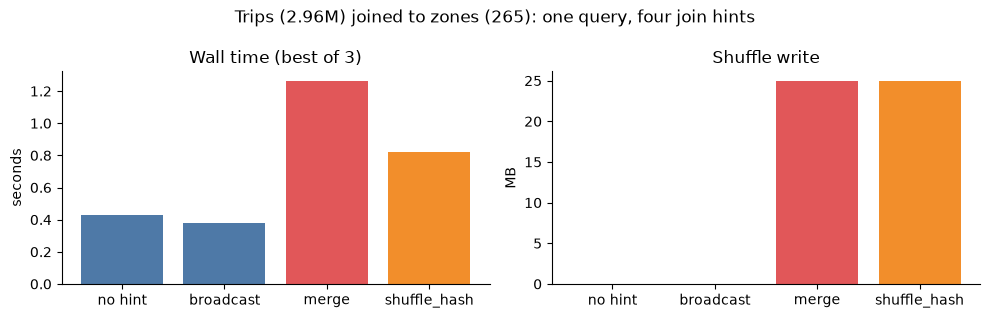

In [6]:
rows = []
for hint in [None, "broadcast", "merge", "shuffle_hash"]:
    qh = revenue_by_borough(zones if hint is None else zones.hint(hint))
    r = measure(hint or "no hint", lambda hint=hint: revenue_by_borough(zones if hint is None else zones.hint(hint)).collect(), reps=3)
    r["join in plan"] = join_ops(qh)
    rows.append(r)
hints = pd.DataFrame(rows).drop(columns="result")
print(hints.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
colors = ["#4E79A7", "#4E79A7", "#E15759", "#F28E2B"]
ax[0].bar(hints["query"], hints["seconds"], color=colors); ax[0].set(title="Wall time (best of 3)", ylabel="seconds")
ax[1].bar(hints["query"], hints["shuffle MB"], color=colors); ax[1].set(title="Shuffle write", ylabel="MB")
plt.suptitle("Trips (2.96M) joined to zones (265): one query, four join hints")
plt.tight_layout(); plt.show()

*Insight: The `merge` and `shuffle_hash` hints both shuffle the same bytes as the forced sort-merge join, because
both shuffle the trips. Shuffle hash skips the sort, so it is faster than sort-merge here (0.82 s against 1.26 s). Both are
slower than the broadcast (0.38 s to 0.43 s). A hint is a tool for the cases where the optimizer estimates sizes wrongly; for a 265-row
table the default is already right.*

## 4. A Large-Large Join

`core` and `pay` both have one row per trip (2.96M rows each), so neither side is small. The query joins them on
`trip_id` and computes the average tip share per pickup zone. This is the normal case for a sort-merge join. The
`SHUFFLE_HASH` hint and a forced `BROADCAST` of the `pay` side are measured for comparison.

In [7]:
def tip_share(pay_df):
    return (core.join(pay_df, "trip_id").where("fare_amount > 0")
            .groupBy("PULocationID").agg(F.avg(F.col("tip_amount") / F.col("fare_amount")).alias("tip_share")))

rows = []
for label, p in [("default", pay), ("shuffle_hash hint", pay.hint("shuffle_hash")), ("broadcast hint", pay.hint("broadcast"))]:
    qq = tip_share(p)
    r = measure(label, lambda p=p: tip_share(p).collect(), reps=2)
    r["join in plan"] = join_ops(qq)
    rows.append(r)
big = pd.DataFrame(rows).drop(columns="result")
print(big.to_string(index=False))
print("plan of the default:"); show_plan(tip_share(pay))

            query  seconds  shuffle MB  stages      join in plan
          default     1.79        62.6       4     SortMergeJoin
shuffle_hash hint     3.27        62.6       4  ShuffledHashJoin
   broadcast hint     3.34         0.0       3 BroadcastHashJoin
plan of the default:
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[PULocationID#33], functions=[avg((tip_amount#39 / fare_amount#38))])
   +- Exchange hashpartitioning(PULocationID#33, 8), ENSURE_REQUIREMENTS, [plan_id=4988]
      +- HashAggregate(keys=[PULocationID#33], functions=[partial_avg((tip_amount#39 / fare_amount#38))])
         +- Project [PULocationID#33, fare_amount#38, tip_amount#39]
            +- SortMergeJoin [trip_id#31L], [trip_id#36L], Inner
               :- Sort [trip_id#31L ASC NULLS FIRST], false, 0
               :  +- Exchange hashpartitioning(trip_id#31L, 8), ENSURE_REQUIREMENTS, [plan_id=4980]
               :     +- Filter isnotnull(trip_id#31L)
               :        +- FileScan parquet [

*Insight: With two large sides the default is a sort-merge join that shuffles both tables (see the two `Exchange`
nodes in the plan). It shuffled 62.6 MB and was the fastest of the three (1.79 s). The
shuffle hash hint took 3.27 s and the broadcast hint 3.34 s. The broadcast hint still works at this size, because the pruned `pay` side (trip_id plus two
amounts, 2.96M rows) fits in the 1.5 GB driver, but it puts the whole table into the driver and into every executor;
on a cluster with many executors and a larger table this is how jobs fail with out-of-memory errors. The safe
default for large-large joins is sort-merge; the real fix is to read less: filter and aggregate before the join.*

## 5. AQE Changes the Plan at Runtime

The optimizer estimates sizes **before** the query runs. A filter like `tip_amount > 50` keeps few rows, but
Spark does not know this without statistics, so the initial plan is a sort-merge join. **Adaptive Query Execution**
(AQE, on by default since Spark 3.2) re-plans after each shuffle stage, using the real sizes. When one side turns
out to be small, AQE replaces the sort-merge join with a broadcast hash join.

On this small data, the planner already broadcasts the filtered side with the default threshold. To show the AQE
switch, the cell turns off broadcasts in the planner (`spark.sql.autoBroadcastJoinThreshold = -1`). It keeps the
runtime limit of AQE (`spark.sql.adaptive.autoBroadcastJoinThreshold = 10m`).

In [8]:
def big_tips():
    return core.join(pay.where("tip_amount > 50"), "trip_id").groupBy("PULocationID").count()

spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")             # the planner never broadcasts
spark.conf.set("spark.sql.adaptive.autoBroadcastJoinThreshold", "10m")   # AQE can broadcast at run time
q_aqe = big_tips()
print("before running:", join_ops(q_aqe), "| isFinalPlan =", "isFinalPlan=true" in plan_text(q_aqe))
res_on = measure("AQE on", lambda: big_tips().collect(), reps=2)
q_aqe.collect()
print("after running: ", join_ops(q_aqe), "| isFinalPlan =", "isFinalPlan=true" in plan_text(q_aqe))
show_plan(q_aqe)
print("rows with tip > 50:", pay.where("tip_amount > 50").count())

before running: SortMergeJoin | isFinalPlan = False


after running:  BroadcastHashJoin, SortMergeJoin | isFinalPlan = True
AdaptiveSparkPlan isFinalPlan=true
+- == Final Plan ==
   ResultQueryStage 4
   +- *(4) HashAggregate(keys=[PULocationID#33], functions=[count(1)])
      +- AQEShuffleRead coalesced
         +- ShuffleQueryStage 3
            +- Exchange hashpartitioning(PULocationID#33, 8), ENSURE_REQUIREMENTS, [plan_id=5680]
               +- *(3) HashAggregate(keys=[PULocationID#33], functions=[partial_count(1)])
                  +- *(3) Project [PULocationID#33]
                     +- *(3) BroadcastHashJoin [trip_id#31L], [trip_id#36L], Inner, BuildRight, false, false
                        :- AQEShuffleRead local
                        :  +- ShuffleQueryStage 0
                        :     +- Exchange hashpartitioning(trip_id#31L, 8), ENSURE_REQUIREMENTS, [plan_id=5548]
                        :        +- *(1) Filter isnotnull(trip_id#31L)
                        :           +- *(1) ColumnarToRow
                        :  

In [9]:
spark.conf.set("spark.sql.adaptive.enabled", "false")
q_off = big_tips()
res_off = measure("AQE off", lambda: big_tips().collect(), reps=2)
print("AQE off plan:", join_ops(q_off))
spark.conf.set("spark.sql.adaptive.enabled", "true")
spark.conf.unset("spark.sql.autoBroadcastJoinThreshold")
spark.conf.unset("spark.sql.adaptive.autoBroadcastJoinThreshold")
print(pd.DataFrame([res_on, res_off]).drop(columns="result").to_string(index=False))

AQE off plan: SortMergeJoin
  query  seconds  shuffle MB  stages
 AQE on     1.24        24.8       5
AQE off     0.89        24.8       4


`explain()` on the same DataFrame after the action shows the final plan (`isFinalPlan=true`): AQE kept the shuffle
of the filtered side (it had to run it to learn the size), then planned a `BroadcastHashJoin` and read the large
side's shuffle output locally (`AQEShuffleRead local`) instead of a sort-merge join.

*Insight: AQE turned the sort-merge join into a broadcast join after it saw that only 593 rows passed the filter.
In this run, the AQE query was slower (1.24 s against 0.89 s). Both sides were already shuffled before AQE could
change the plan (24.8 MB in both runs), and the extra broadcast stage (5 stages instead of 4) cost more than the
sort it saved. The switch pays off when sorting the large side is expensive, for example when the sort spills
to disk. Look at the final plan (after the action, or in the SQL tab of
the Spark UI) when you analyse a slow join: the initial plan can be different.*

## 6. Join Pitfalls

**Duplicate keys.** A join returns one row for every matching **pair**. If the "lookup" side has two rows for a key,
every matching row on the other side appears twice. This happens when a dimension table keeps history
(two versions of a zone) and nobody filters the current version.

In [10]:
zones_dup = zones.union(zones.where("Borough = 'Manhattan'").withColumn("service_zone", F.lit("Yellow Zone (v2)")))
n_trips = trips.count()
for name, z in [("clean zones", zones), ("Manhattan rows twice", zones_dup)]:
    j = trips.join(z, trips.PULocationID == z.LocationID)
    rev = j.agg(F.sum("total_amount")).first()[0]
    print(f"{name:<22} zone rows {z.count():>3} | joined rows {j.count():>9,} | revenue {rev / 1e6:6.2f} M$")
print(f"trips: {n_trips:,}  -> check: count rows per key on the lookup side before you join")
print(zones_dup.groupBy("LocationID").count().where("count > 1").count(), "LocationIDs appear more than once")

clean zones            zone rows 265 | joined rows 2,964,606 | revenue  79.46 M$


Manhattan rows twice   zone rows 334 | joined rows 5,611,539 | revenue 138.70 M$
trips: 2,964,606  -> check: count rows per key on the lookup side before you join


69 LocationIDs appear more than once


**Many-to-many.** If both sides have many rows per key, the output has $\sum_k n_k^{left} \cdot n_k^{right}$ rows.
Joining January trips to February trips on the pickup zone ("compare each trip with each trip of the same zone")
looks harmless, but the formula shows the size. Compute it from two small aggregations before you run such a join.
The cell then runs the join for one hour of one day only.

In [11]:
feb = (spark.read.parquet(str(datasets.taxi("2024-02")))
       .where("tpep_pickup_datetime >= '2024-02-01' AND tpep_pickup_datetime < '2024-03-01'"))
nj = trips.groupBy("PULocationID").agg(F.count("*").alias("n_jan"))
nf = feb.groupBy("PULocationID").agg(F.count("*").alias("n_feb"))
expected = nj.join(nf, "PULocationID").agg(F.sum(F.col("n_jan") * F.col("n_feb"))).first()[0]
print(f"full month x month join on zone would return {expected:,} rows ({expected / n_trips:,.0f} per January trip)")

jan_h = trips.where("tpep_pickup_datetime >= '2024-01-17 08:00' AND tpep_pickup_datetime < '2024-01-17 09:00'")
feb_h = feb.where("tpep_pickup_datetime >= '2024-02-14 08:00' AND tpep_pickup_datetime < '2024-02-14 09:00'")
pairs = jan_h.select("PULocationID").join(feb_h.select("PULocationID"), "PULocationID")
r = measure("one hour x one hour", lambda: pairs.count(), reps=1)
print(f"one hour: {jan_h.count():,} x {feb_h.count():,} trips -> {r['result']:,} joined rows in {r['seconds']} s")

full month x month join on zone would return 233,416,307,687 rows (78,734 per January trip)


one hour: 5,958 x 6,349 trips -> 1,014,011 joined rows in 0.78 s


*Insight: Two inputs of about 6,000 rows each give 1,014,011 output rows. The reason: the busy zones (Midtown, Upper
East Side) have hundreds of trips on both sides. For the full months the formula predicts 233 billion rows: the job
would never finish. A many-to-many join is almost always a modelling error: aggregate one side to one row per key
first.*

**Null keys.** In SQL, `NULL = NULL` is not true, so rows with a null key never match in an equi-join. Spark adds an
`isnotnull` filter to inner joins for this reason. `passenger_count` is null for some trips; a lookup table that has a
row for "unknown" (null) does not match them with `==`, only with the null-safe operator `<=>` (`eqNullSafe`).

In [12]:
pc = spark.createDataFrame([(0, "no passenger recorded"), (1, "single"), (2, "pair"), (3, "group"), (4, "group"),
                            (5, "group"), (6, "group"), (None, "unknown")], "passenger_count int, label string")
t = trips.select("trip_id", F.col("passenger_count").cast("int").alias("pcount"))
n_null = t.where("pcount IS NULL").count()
inner = t.join(pc, t.pcount == pc.passenger_count)
left = t.join(pc, t.pcount == pc.passenger_count, "left")
safe = t.join(pc, t.pcount.eqNullSafe(pc.passenger_count))
print(f"trips with null passenger_count: {n_null:,}")
print(f"inner join  (==)  : {inner.count():>9,} rows")
print(f"left join   (==)  : {left.count():>9,} rows, label null for {left.where('label IS NULL').count():,}")
print(f"inner join  (<=>) : {safe.count():>9,} rows, 'unknown' for {safe.where(F.col("label") == "unknown").count():,}")
print("isnotnull filter in the == plan:", "isnotnull(pcount" in plan_text(inner))

trips with null passenger_count: 140,162


inner join  (==)  : 2,824,384 rows


left join   (==)  : 2,964,606 rows, label null for 140,222


inner join  (<=>) : 2,964,546 rows, 'unknown' for 140,162
isnotnull filter in the == plan: False


*Insight: The plain inner join silently drops every trip with a null passenger count, and the trips with counts 7–9
that have no lookup row. A left join keeps them but leaves the label empty; only the null-safe join maps null to
"unknown". Count the rows before and after every join in a pipeline: a changed count is the first sign of a key
problem. A second risk of null keys appears in outer joins on large tables: all null keys hash to the same shuffle
partition, so one task gets much more work (data skew, Lesson 07).*

| Situation | Use |
| :--- | :--- |
| one side small (lookup, dimension, < ~100 MB in memory) | broadcast hash join (automatic below 10 MB, or a hint) |
| both sides large | sort-merge join (default); filter and pre-aggregate first |
| one side small only after a filter | let AQE switch to broadcast (keep AQE on) |
| sort is the bottleneck and partitions are small | shuffle hash join hint |
| non-equi condition (ranges, `<`) | broadcast nested loop join; keep that side small, or bucket the range into an equi-key |

## Real-World Use Case or Analogy

A broadcast join is like giving every cashier in a supermarket a copy of the price list: each cashier works alone
and fast. A sort-merge join is like two large piles of paper forms that must be matched by customer number: both
piles are first sorted into boxes by number, then each box is matched by one person.

Companies join large fact tables (orders, clicks, trips) to small dimension tables (products, countries, zones) all
the time, and broadcast joins make these joins cheap. Large-large joins (orders to payments, sessions to events) run
as sort-merge joins; teams reduce their cost by filtering early, by storing both tables bucketed or clustered on the
join key, and by checking key uniqueness in data quality tests.

In [13]:
spark.stop()